# Imports & Data Cleaning 

In [5]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt, joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix)
from imblearn.over_sampling import SMOTE

data = pd.read_csv("fintech_savings_dormancy.csv").drop_duplicates(subset=['customer_id'])
data = data.fillna({'employment_type': 'Salaried', 'app_plan': 'Unknown', 'failed_payments_6m': 0})

for col in ['annual_income_inr', 'monthly_spend_inr', 'average_balance_inr', 'days_since_last_login']:
    data[col] = data[col].fillna(data[col].median())

data['days_since_last_login'] = np.log1p(data['days_since_last_login'].clip(lower=0))

for col in ['annual_income_inr', 'monthly_spend_inr', 'average_balance_inr']:
    Q1, Q3 = data[col].quantile([0.25, 0.75])
    data[col] = data[col].clip(max(0, Q1 - 1.5*(Q3 - Q1)), Q3 + 1.5*(Q3 - Q1))

print("Cleaned! Missing values left:", data.isnull().sum().sum())


Cleaned! Missing values left: 0


# Exploratory Data Analysis — EDA Charts

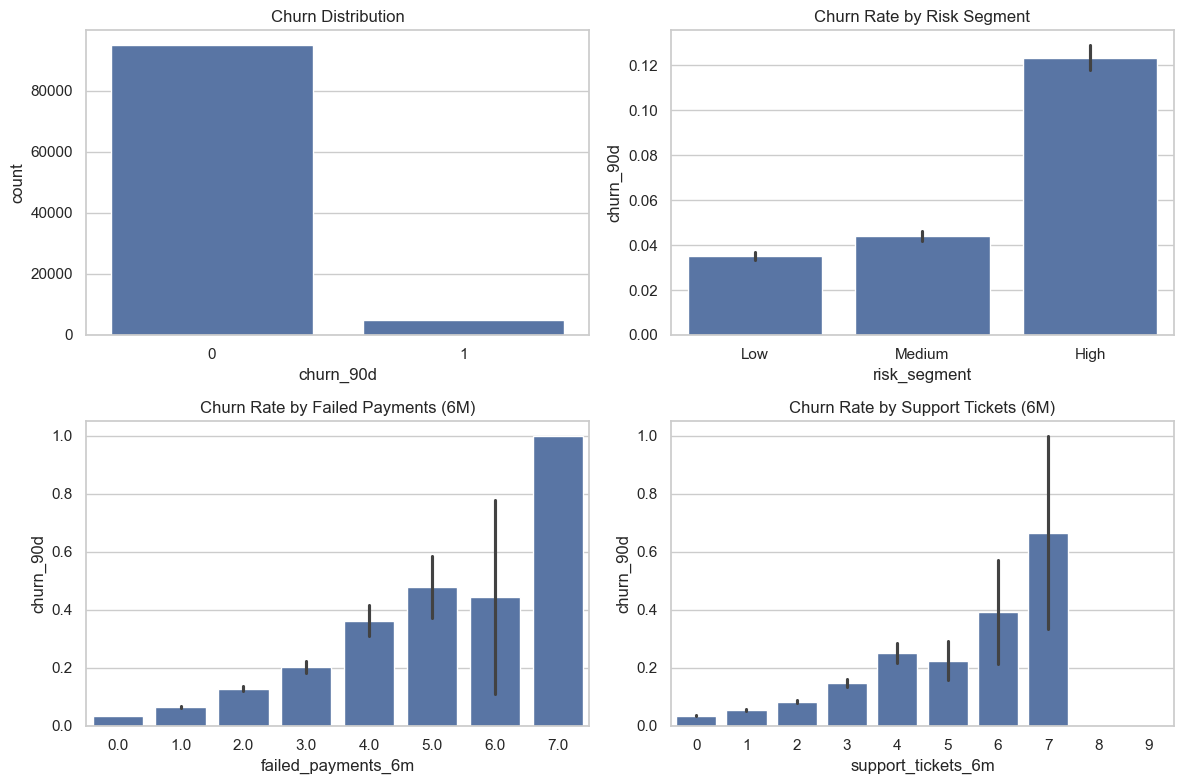

In [22]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(x='churn_90d', data=data, ax=ax[0, 0])
ax[0, 0].set_title("Churn Distribution")

sns.barplot(x='risk_segment', y='churn_90d', data=data, ax=ax[0, 1])
ax[0, 1].set_title("Churn Rate by Risk Segment")

sns.barplot(x='failed_payments_6m', y='churn_90d', data=data, ax=ax[1, 0])
ax[1, 0].set_title("Churn Rate by Failed Payments (6M)")

sns.barplot(x='support_tickets_6m', y='churn_90d', data=data, ax=ax[1, 1])
ax[1, 1].set_title("Churn Rate by Support Tickets (6M)")

plt.tight_layout()
plt.show()


In [23]:
fs = RandomForestClassifier(n_estimators=1000, max_depth=3, random_state=77, n_jobs=-1)
fs.fit(val, tar)

pd.DataFrame({
    "col": val.columns,
    "scr": fs.feature_importances_ * 100
}).sort_values("scr", ascending=False)


,col,scr
11,friction,32.820164
6,failed_payments_6m,23.232336
7,support_tickets_6m,14.559349
2,account_tenure_months,12.916460
22,risk_segment_Low,5.399634
8,days_since_last_login,4.057000
10,auto_save_enabled,1.957957
23,risk_segment_Medium,1.881547
3,monthly_transactions,1.455668
4,monthly_spend_inr,0.549299


# Feature Engineering, Train-Test Split, SMOTE & Scaling

In [24]:
data['friction'] = data['failed_payments_6m'] + data['support_tickets_6m']
val = pd.get_dummies(data.drop("churn_90d", axis=1).set_index("customer_id"), drop_first=True, dtype=int)
tar = data['churn_90d']

train_full, test_data, train_lab_full, test_lab = train_test_split(val, tar, test_size=0.2, random_state=77, stratify=tar)
train_data, val_data, train_lab, val_lab = train_test_split(train_full, train_lab_full, test_size=0.2, random_state=77, stratify=train_lab_full)

os_val, os_tar = SMOTE(random_state=77).fit_resample(train_data, train_lab)
scaler = StandardScaler()
os_val_sc, val_sc, test_sc = scaler.fit_transform(os_val), scaler.transform(val_data), scaler.transform(test_data)

print("Ready for training! Train shape:", os_val_sc.shape)


Ready for training! Train shape: (121600, 24)


# Train & Compare All 3 Models

In [25]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=77),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=77, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=10, random_state=77, n_jobs=-1)
}

metrics_list = []
for name, m in models.items():
    m.fit(os_val_sc, os_tar)
    p, pr = m.predict(test_sc), m.predict_proba(test_sc)[:, 1]
    metrics_list.append({
        "Model": name,
        "Accuracy": round(accuracy_score(test_lab, p) * 100, 2),
        "Precision": round(precision_score(test_lab, p, zero_division=0) * 100, 2),
        "Recall": round(recall_score(test_lab, p) * 100, 2),
        "F1-Score": round(f1_score(test_lab, p) * 100, 2),
        "ROC-AUC": round(roc_auc_score(test_lab, pr) * 100, 2),
        "PR-AUC": round(average_precision_score(test_lab, pr) * 100, 2)
    })

metrics_df = pd.DataFrame(metrics_list)
print(metrics_df.to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Logistic Regression     90.27      12.99    16.6     14.57    64.68    9.44
      Random Forest     90.44      16.53    22.5     19.06    67.94   11.54
        Extra Trees     87.94      12.81    24.3     16.78    64.38    9.37


# Threshold Optimization & Confusion Matrix

In [26]:
best_model = models["Random Forest"]
val_probs = best_model.predict_proba(val_sc)[:, 1]
best_t = max([0.3, 0.4, 0.5, 0.6, 0.7], key=lambda t: f1_score(val_lab, (val_probs >= t).astype(int)))

test_probs = best_model.predict_proba(test_sc)[:, 1]
test_preds = (test_probs >= best_t).astype(int)

print(f"Best Validation Threshold: {best_t} | Test F1: {f1_score(test_lab, test_preds)*100:.2f}%")
print("Confusion Matrix:\n", confusion_matrix(test_lab, test_preds))


Best Validation Threshold: 0.5 | Test F1: 19.06%
Confusion Matrix:
 [[17864  1136]
 [  775   225]]


# Export Risk CSV & Save Model for Streamlit 

In [27]:
risk = np.where(test_probs >= 0.65, 'High Risk', np.where(test_probs >= 0.35, 'Medium Risk', 'Low Risk'))
report = pd.DataFrame({'customer_id': test_data.index, 'probability': np.round(test_probs, 4), 'churn': test_preds, 'risk': risk})
report.to_csv('churn_risk_report.csv', index=False)
print("Risk Breakdown:\n", report['risk'].value_counts())

joblib.dump({'model': best_model, 'scaler': scaler, 'cols': list(val.columns), 't': best_t, 'metrics': metrics_df}, 'churn_model.pkl')
print("Saved 'churn_risk_report.csv' and 'churn_model.pkl' successfully!")


Risk Breakdown:
 risk
Low Risk       17177
Medium Risk     2268
High Risk        555
Name: count, dtype: int64
Saved 'churn_risk_report.csv' and 'churn_model.pkl' successfully!


# Streamlit Deployment 

In [33]:
import os, subprocess, time, webbrowser

app_code = '''import streamlit as st, pandas as pd, numpy as np, joblib

st.title("🏦 FinTech Churn Predictor")
b = joblib.load('churn_model.pkl')

# Customer Inputs
age = st.slider("Age", 18, 80, 35)
region = st.selectbox("Region", ["Metro", "Tier 1", "Tier 2", "Rural"])
emp = st.selectbox("Employment", ["Salaried", "Self-employed", "Student", "Unemployed"])
income = st.number_input("Annual Income (₹)", 5000, 5000000, 50000)
tenure = st.slider("Account Tenure (Months)", 1, 120, 24)
plan = st.selectbox("App Plan", ["Basic", "Plus", "Premium", "Unknown"])
risk = st.selectbox("Risk Segment", ["Low", "Medium", "High"])
txns = st.slider("Monthly Transactions", 0, 100, 8)
spend = st.number_input("Monthly Spend (₹)", 0, 500000, 800)
bal = st.number_input("Average Balance (₹)", 0, 2000000, 7500)
fail = st.slider("Failed Payments (6M)", 0, 15, 0)
tix = st.slider("Support Tickets (6M)", 0, 15, 0)
login = st.slider("Days Since Last Login", 0, 365, 10)
goal = st.selectbox("Has Savings Goal? (1=Yes, 0=No)", [0, 1])
auto = st.selectbox("Auto-Save Enabled? (1=Yes, 0=No)", [0, 1])

# Prepare Data & Predict
row = pd.DataFrame([{'age': age, 'region': region, 'employment_type': emp, 'annual_income_inr': income, 'account_tenure_months': tenure, 'app_plan': plan, 'risk_segment': risk, 'monthly_transactions': txns, 'monthly_spend_inr': spend, 'average_balance_inr': bal, 'failed_payments_6m': fail, 'support_tickets_6m': tix, 'days_since_last_login': np.log1p(login), 'has_savings_goal': goal, 'auto_save_enabled': auto, 'friction': fail + tix}])
X_in = b['scaler'].transform(pd.get_dummies(row, dtype=int).reindex(columns=b['cols'], fill_value=0))

if st.button("Predict Churn Risk"):
    p = float(b['model'].predict_proba(X_in)[0][1])
    st.metric("90-Day Churn Probability", f"{p*100:.2f}%")
    st.write("Risk Category:", "🔴 High Risk" if p >= 0.65 else ("🟡 Medium Risk" if p >= 0.35 else "🟢 Low Risk"))
    st.info("Advice: " + ("Offer cashback & priority support." if p >= 0.65 else ("Send Auto-Save reminder." if p >= 0.35 else "Cross-sell Plus/Premium plan.")))

st.subheader("📊 Model Evaluation Metrics")
st.dataframe(b['metrics'])
'''

with open("fintech_churn_app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

subprocess.run(["pkill", "-9", "-f", "streamlit"])
time.sleep(1)
subprocess.Popen(["streamlit", "run", os.path.abspath("fintech_churn_app.py"), "--server.port", "8505"])
time.sleep(3)
webbrowser.open("http://localhost:8505")


2026-11-17 20:51:26.853 Uvicorn server started on :::8505



  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8505
  Network URL: http://192.168.31.187:8505

  Help agents write better Streamlit apps?
  Install the official Streamlit skills by running streamlit skills in your terminal.



True